# REPORT ECOMMERCE

In [1]:
import sys
sys.path.append("../src")

import metrics as M
import viz as V

In [2]:
from io_utils import load_data

data = load_data("../data/ecommerce_sales.csv")

# Total revenue per category & TOP-3

Revenue per category:
Sports: 734653.42
Clothing: 586744.91
Home: 511070.87
Electronics: 1364228.07
Toys: 143015.99
Beauty: 163053.97


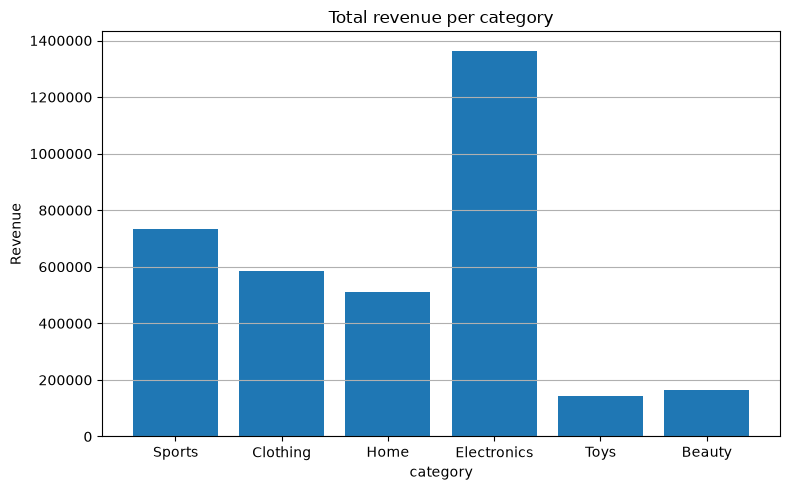

In [3]:
total_per_category = M.revenue_per_column(data, "category")
print("Revenue per category:")
for row in total_per_category:
    print(f"{row["group"]}: {row["total"]:.2f}")

summary = M.revenue_per_column(data, "category")
V.plot_revenue_per_column(summary, "category", "Total revenue per category")

- The TOP-3 categories are: 
**1. Electronics** *1.364.228,07*
**2. Sports** *734.653,42*
**3. Clothing** *586.744,91*
- The category **Electronics** has clearly the biggest total revenue of all categories. The revenue is nearly double as much as the second biggest category **Sports**.

# Total revenue and number of units

In [9]:
total_revenue = M.get_total(data, "revenue")
total_units = M.get_total(data, "units")

print(f"Total revenue:  {total_revenue:.2f}")
print(f"Total units: {total_units:.2f}")

Total revenue:  3502767.23
Total units: 7463.00


Revenue per city
Stockholm: 1227201.94
Malmö: 567926.32
Uppsala: 551478.42
Göteborg: 859019.65
Västerås: 297140.90


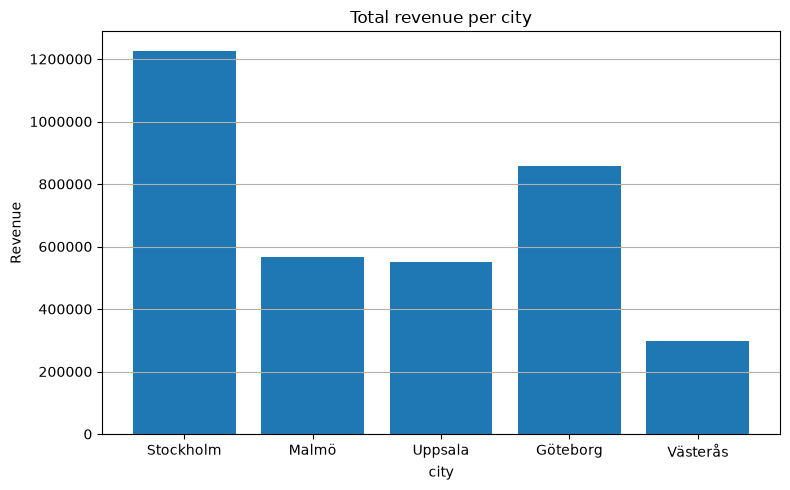

In [10]:
revenue_per_city = M.revenue_per_column(data, "city")
print("Revenue per city")

for row in revenue_per_city:
    print(f"{row["group"]}: {row["total"]:.2f}")

summary = M.revenue_per_column(data, "city")
V.plot_revenue_per_column(summary, "city", "Total revenue per city")

## Average Order Value (AOV)

In [11]:
from aov_top3 import average_order_value

aov = average_order_value(data)
print(f"Average Order Value (AOV): {aov:.2f}")

Average Order Value (AOV): 1401.11


AOV visar den genomsnittliga intäkten per order. Det beräknas genom att dela den totala intäkten med antalet unika order. För vårt dataset är AOV cirka 1401,11.

In [12]:
# Samla försäljningen efter kategori
category_data = {}

for row in data:
    category = row["category"]
    if category not in category_data:
        category_data[category] = []
    category_data[category].append(row)

# Beräkna AOV för varje kategori
for category, rows in category_data.items():
    print(f"{category}: {average_order_value(rows):.2f}")

Sports: 1770.25
Clothing: 1152.74
Home: 1043.00
Electronics: 2207.49
Toys: 630.03
Beauty: 676.57


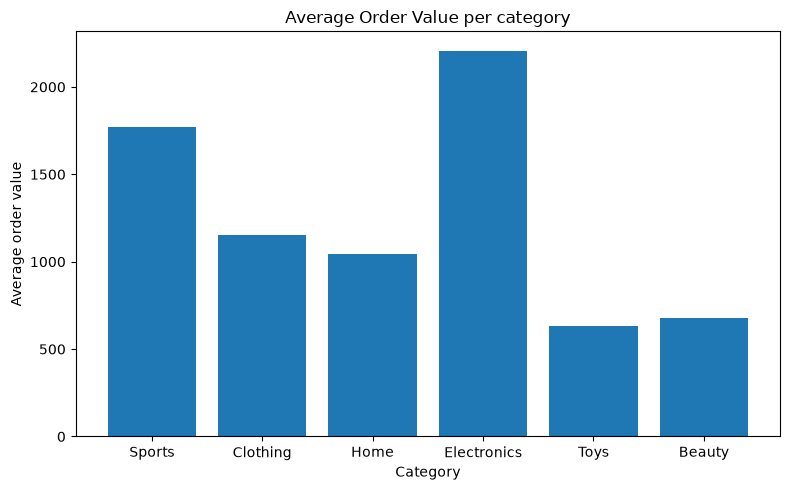

In [13]:
import matplotlib.pyplot as plt

categories = []
aov_values = []

for category, rows in category_data.items():
    categories.append(category)
    aov_values.append(average_order_value(rows))

plt.figure(figsize=(8, 5))
plt.bar(categories, aov_values)
plt.title("Average Order Value per category")
plt.xlabel("Category")
plt.ylabel("Average order value")
plt.tight_layout()
plt.show()

Diagrammet jämför genomsnittligt ordervärde mellan kategorierna. Electronics har högst AOV, cirka 2207,49 per order, medan Toys har lägst, cirka 630,03.

## Rekommendationer

Adem: Jag tycker att företaget kan testa att göra mer reklam för elektronik, eftersom Electronics har högst genomsnittligt ordervärde. För Toys, som har lägst ordervärde, kan paketerbjudanden vara ett sätt att få kunder att köpa fler varor i samma beställning. Sedan behöver företaget följa upp om det ökar både försäljningen och vinsten.